# 04 · Correlaciones y tendencias en el tiempo

Dos preguntas:

1. **¿Qué variables se mueven juntas?** Matriz de correlación y desfases entre casos, hospitalizados y muertes.
2. **¿Cómo cambian a lo largo de la pandemia?** Tendencias nacionales, por región y por estado.

Partimos de los datos con las variables del notebook 03 y usamos los 50 estados y DC.

## 0. Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.graficos import (AMARILLO, AZUL, GRIS, NARANJA, TEXTO, TEXTO_SUAVE, VERDE, aplicar_estilo, formato_miles,
                          lineas_olas, miles)
from src.variables import OLAS, REGIONES

aplicar_estilo()

RUTA_VARIABLES = RAIZ / "data" / "processed" / "covid_estados_variables.csv"
if not RUTA_VARIABLES.exists():
    raise FileNotFoundError("Ejecuta antes los notebooks 01, 02 y 03: generan " + str(RUTA_VARIABLES.relative_to(RAIZ)))

datos = pd.read_csv(RUTA_VARIABLES, parse_dates=["fecha", "semana"])
estados = datos[~datos["es_territorio"]].sort_values(["estado", "fecha"]).copy()
CORTES = pd.to_datetime(list(OLAS.values())[:2])

# Medias de 7 días por estado de las variables diarias: quitan el ruido del día de la semana.
for columna in ["casos_nuevos", "muertes_nuevas", "tests_nuevos"]:
    estados[columna + "_7d"] = estados.groupby("estado")[columna].transform(
        lambda s: s.rolling(7, min_periods=4).mean())
estados.shape

(18995, 30)

## 1. Matriz de correlación

Usamos siete variables:

- **Cuántos contagios hay:** casos nuevos, tests nuevos y positividad.
- **Cómo de graves son:** hospitalizados actuales, ingresados en UCI y muertes nuevas.
- **La letalidad aparente.**

Empezamos en abril de 2020, cuando ya casi todos los estados informaban. Dejamos fuera los pacientes con
respirador porque solo la mitad de las filas tienen ese dato.

### 1.1 ¿Correlación entre qué? El nivel importa

Hay tres formas de calcularla, y no dan lo mismo:

- **Todas las filas juntas** (cada fila es un estado y un día).
- **La serie nacional:** la suma de los estados, día a día.
- **Dentro de cada estado:** la correlación de cada estado consigo mismo a lo largo del tiempo. Nos quedamos con la
  mediana de los 51 estados.

In [2]:
VARIABLES = {
    "casos_nuevos_7d": "Casos nuevos",
    "tests_nuevos_7d": "Tests nuevos",
    "positividad_7d": "Positividad",
    "hospitalizados_actuales": "Hospitalizados",
    "uci_actuales": "En UCI",
    "muertes_nuevas_7d": "Muertes nuevas",
    "letalidad_aparente": "Letalidad aparente",
}
periodo = estados[estados["fecha"] >= "2020-04-01"]

# 1) Todas las filas juntas.
todas = periodo[list(VARIABLES)].corr()

# 2) Serie nacional: sumas por día (las tasas se recalculan con los totales).
suma = periodo.groupby("fecha")[["casos_nuevos", "tests_nuevos", "muertes_nuevas", "hospitalizados_actuales",
                                  "uci_actuales", "muertes_acum", "casos_acum"]].sum()
nacional = pd.DataFrame({
    "casos_nuevos_7d": suma["casos_nuevos"].rolling(7).mean(),
    "tests_nuevos_7d": suma["tests_nuevos"].rolling(7).mean(),
    "positividad_7d": suma["casos_nuevos"].rolling(7).sum() / suma["tests_nuevos"].rolling(7).sum(),
    "hospitalizados_actuales": suma["hospitalizados_actuales"],
    "uci_actuales": suma["uci_actuales"],
    "muertes_nuevas_7d": suma["muertes_nuevas"].rolling(7).mean(),
    "letalidad_aparente": suma["muertes_acum"] / suma["casos_acum"],
})
serie_nacional = nacional.corr()

# 3) Dentro de cada estado: una matriz por estado y la mediana de las 51.
matrices = [grupo[list(VARIABLES)].corr(min_periods=30) for _, grupo in periodo.groupby("estado")]
dentro = pd.concat(matrices).groupby(level=0).median().loc[list(VARIABLES), list(VARIABLES)]

pares = [("casos_nuevos_7d", "positividad_7d"), ("casos_nuevos_7d", "muertes_nuevas_7d"),
         ("casos_nuevos_7d", "hospitalizados_actuales"), ("tests_nuevos_7d", "letalidad_aparente")]
pd.DataFrame({
    "todas las filas": [todas.loc[a, b] for a, b in pares],
    "serie nacional": [serie_nacional.loc[a, b] for a, b in pares],
    "dentro de cada estado": [dentro.loc[a, b] for a, b in pares],
}, index=[f"{VARIABLES[a]} – {VARIABLES[b]}" for a, b in pares]).round(2)

,todas las filas,serie nacional,dentro de cada estado
Casos nuevos – Positividad,0.21,0.42,0.68
Casos nuevos – Muertes nuevas,0.69,0.68,0.69
Casos nuevos – Hospitalizados,0.90,0.94,0.93
Tests nuevos – Letalidad aparente,-0.04,-0.91,-0.73


La relación entre casos y positividad pasa de **0,21 con todas las filas juntas a 0,68 dentro de cada estado**, y
la de tests y letalidad, de casi 0 a −0,73:

- **Todas las filas juntas** mezclan estados de tamaños muy distintos: California tiene muchos casos con una
  positividad moderada y Idaho, pocos casos con una positividad alta, porque cuenta personas y no muestras
  (notebook 03). Las diferencias entre estados tapan la relación que hay dentro de cada uno.
- **La serie nacional** tiene otro problema: la suma de hospitalizados y UCI cambia cuando un estado empieza a
  informar, no solo cuando cambian los contagios.
- **Dentro de cada estado** se compara cada estado consigo mismo: el tamaño y la forma de contar no cambian. Es la
  pregunta que nos interesa (cuando suben los casos en un sitio, ¿sube también la positividad?), así que usamos
  esta para el mapa de calor.

### 1.2 Mapa de calor

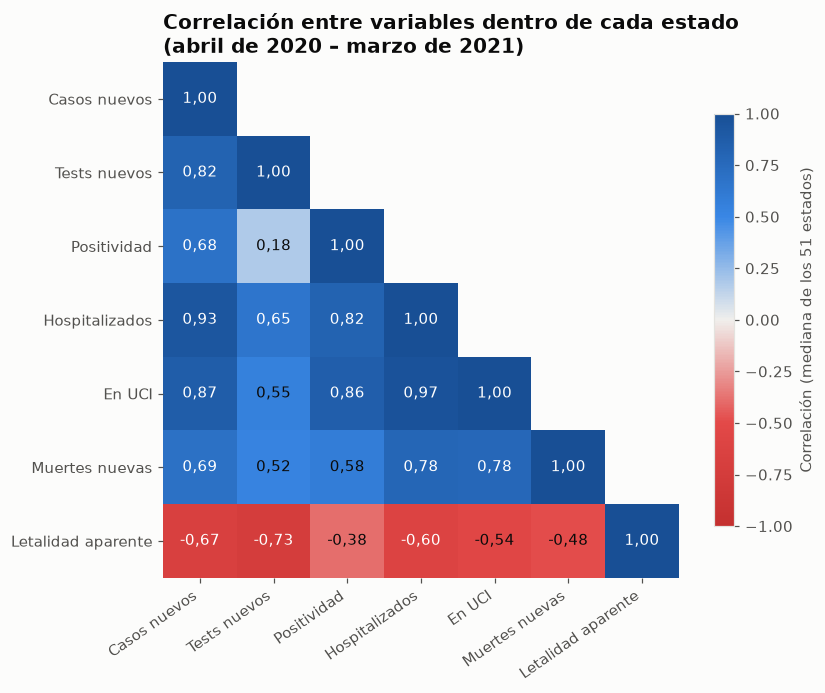

In [3]:
divergente = LinearSegmentedColormap.from_list("divergente", ["#c4302f", "#e34948", "#f0efec", "#3987e5", "#184f95"])
nombres = list(VARIABLES.values())
oculta = np.triu(np.ones_like(dentro, dtype=bool), k=1)   # solo la mitad inferior: la otra es simétrica
matriz = np.ma.masked_array(dentro.values, mask=oculta)

fig, ax = plt.subplots(figsize=(8, 6.4))
imagen = ax.imshow(matriz, cmap=divergente, vmin=-1, vmax=1)
for i in range(len(nombres)):
    for j in range(i + 1):
        valor = dentro.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}".replace(".", ","), ha="center", va="center", fontsize=10,
                color="white" if abs(valor) > 0.6 else TEXTO)
ax.set_xticks(range(len(nombres)), nombres, rotation=35, ha="right")
ax.set_yticks(range(len(nombres)), nombres)
ax.grid(False)
for borde in ax.spines.values():
    borde.set_visible(False)
fig.colorbar(imagen, ax=ax, shrink=0.8, label="Correlación (mediana de los 51 estados)")
ax.set_title("Correlación entre variables dentro de cada estado\n(abril de 2020 – marzo de 2021)")
plt.tight_layout()
plt.show()

Cómo leerlo: azul = se mueven en el mismo sentido; rojo = en sentido contrario; gris = sin relación.

- **Casos, hospitalizados y UCI van casi a la par** (0,87 a 0,93): cuando suben los contagios, los hospitales se
  llenan casi a la vez.
- **Las muertes están algo menos correlacionadas con los casos (0,69).** No es que vayan por libre: llegan más
  tarde, y la correlación del mismo día no lo recoge (apartado 2).
- **Positividad y casos (0,68):** cuando hay más contagios, una mayor parte de los tests sale positiva, porque los
  tests no crecen al mismo ritmo. La positividad va aún más ligada a los hospitalizados (0,82) y a la UCI (0,86)
  que a los propios casos: sube cuando hay muchos contagios sin detectar, que acaban llegando al hospital.
- **La letalidad aparente sale en rojo con casi todo.** Aquí hay que tener cuidado: **correlación no es causa.** La
  letalidad bajó durante todo el periodo (notebook 03) mientras los casos y los tests subían. Las dos variables
  siguen la misma tendencia temporal, y la correlación negativa refleja sobre todo eso. Que más tests hagan bajar
  la letalidad aparente es razonable (se detectan más casos leves), pero esta matriz sola no lo demuestra.

## 2. Desfases: quién va antes

La correlación del mismo día puede engañar si una variable reacciona más tarde. Desplazamos una serie *k* días
hacia delante y vemos con qué desfase la correlación es más alta (de nuevo, mediana de los 51 estados).

In [4]:
def correlacion_con_desfase(origen, destino, desfases=range(0, 36)):
    """Mediana entre estados de corr(origen desplazado k días, destino), para cada k."""
    curva = {}
    for k in desfases:
        por_estado = [g[origen].shift(k).corr(g[destino]) for _, g in periodo.groupby("estado")]
        curva[k] = np.nanmedian(por_estado)
    return pd.Series(curva)

desfases = {
    "Casos → hospitalizados": correlacion_con_desfase("casos_nuevos_7d", "hospitalizados_actuales"),
    "Hospitalizados → muertes": correlacion_con_desfase("hospitalizados_actuales", "muertes_nuevas_7d"),
    "Casos → muertes": correlacion_con_desfase("casos_nuevos_7d", "muertes_nuevas_7d"),
}
pd.DataFrame({nombre: {"mejor desfase (días)": curva.idxmax(), "correlación con ese desfase": round(curva.max(), 2),
                       "correlación sin desfase": round(curva[0], 2)}
              for nombre, curva in desfases.items()}).T

,mejor desfase (días),correlación con ese desfase,correlación sin desfase
Casos → hospitalizados,3.0,0.95,0.93
Hospitalizados → muertes,11.0,0.90,0.78
Casos → muertes,20.0,0.83,0.69


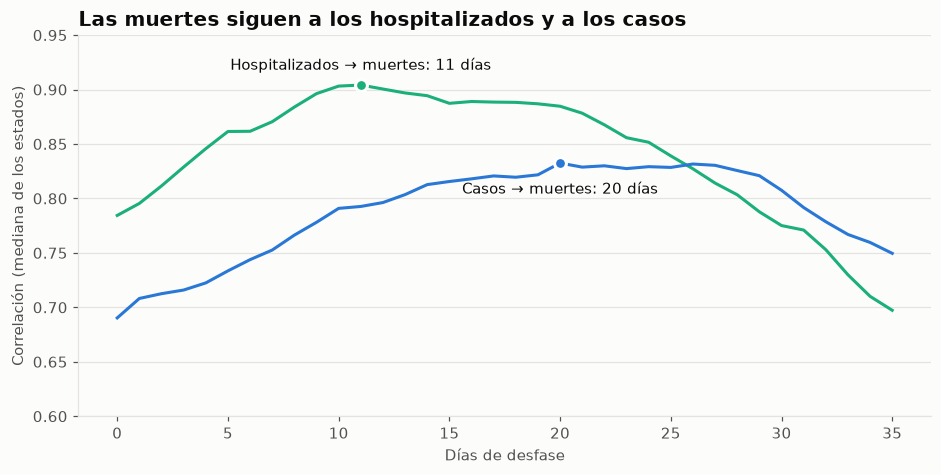

In [5]:
fig, ax = plt.subplots()
for (nombre, curva), color, abajo in zip(list(desfases.items())[1:], [VERDE, AZUL], [False, True]):
    ax.plot(curva.index, curva.values, color=color)
    mejor = curva.idxmax()
    ax.scatter(mejor, curva[mejor], s=60, color=color, edgecolors="white", linewidths=2, zorder=3)
    ax.annotate(f"{nombre}: {mejor} días", xy=(mejor, curva[mejor]), xytext=(0, -20 if abajo else 10),
                textcoords="offset points", ha="center", color=TEXTO)
ax.set_ylim(0.6, 0.95)
ax.set_xlabel("Días de desfase")
ax.set_ylabel("Correlación (mediana de los estados)")
ax.set_title("Las muertes siguen a los hospitalizados y a los casos")
ax.grid(axis="x", visible=False)
plt.show()

Sale una cadena clara:

1. **Casos → hospitalizados: unos 3 días.** Los hospitalizados son casi un reflejo inmediato de los casos.
2. **Hospitalizados → muertes: unos 11 días.**
3. **Casos → muertes: unos 20 días** (correlación 0,83 frente a 0,69 sin desfase). La curva azul es bastante plana
   entre los 15 y los 28 días, así que más que un número exacto es "unas tres semanas". En el notebook 01, con la
   serie nacional, salían 23 días: las dos cifras cuentan lo mismo.

Además, los hospitalizados anticipan las muertes con una correlación más alta (0,90) que los casos. Son el mejor
**aviso adelantado** de las muertes que llegarán casi dos semanas después.

## 3. Tendencias nacionales

Cada variable va en su propio panel, con su propia escala: casos y muertes se mueven en órdenes de magnitud
distintos y un eje doble confundiría. Las líneas discontinuas marcan los cortes entre olas.

In [6]:
desde_marzo = estados[estados["fecha"] >= "2020-03-01"]
suma = desde_marzo.groupby("fecha")[["casos_nuevos", "muertes_nuevas", "tests_nuevos",
                                      "hospitalizados_actuales"]].sum()
informan = desde_marzo.groupby("fecha")["hospitalizados_actuales"].count()
tendencias = pd.DataFrame({
    "casos": suma["casos_nuevos"].rolling(7).mean(),
    "hospitalizados": suma["hospitalizados_actuales"],
    "muertes": suma["muertes_nuevas"].rolling(7).mean(),
    "positividad": suma["casos_nuevos"].rolling(7).sum() / suma["tests_nuevos"].rolling(7).sum() * 100,
})
cobertura_completa = informan[informan >= 47].index.min()   # desde aquí informan 47 o más de los 51
print("Hospitalizados: 47 o más estados informan desde el", cobertura_completa.date())

Hospitalizados: 47 o más estados informan desde el 2020-05-12


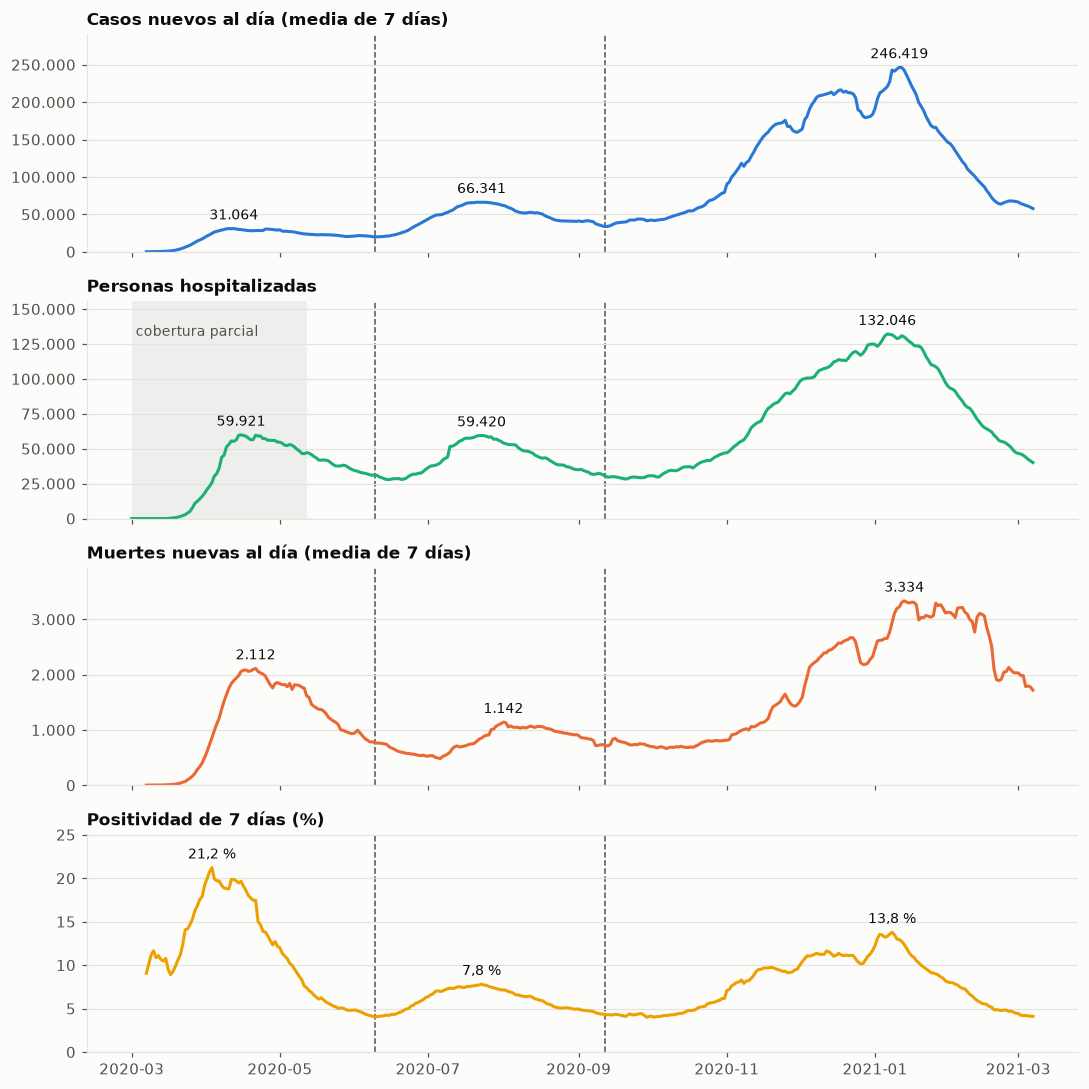

In [7]:
paneles = [
    ("casos", "Casos nuevos al día (media de 7 días)", AZUL),
    ("hospitalizados", "Personas hospitalizadas", VERDE),
    ("muertes", "Muertes nuevas al día (media de 7 días)", NARANJA),
    ("positividad", "Positividad de 7 días (%)", AMARILLO),
]
fig, ejes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
for ax, (columna, titulo, color) in zip(ejes, paneles):
    serie = tendencias[columna]
    ax.plot(serie.index, serie, color=color)
    lineas_olas(ax, CORTES)
    for tramo in [serie.loc[:CORTES[0]], serie.loc[CORTES[0]:CORTES[1]], serie.loc[CORTES[1]:]]:
        pico = tramo.idxmax()
        texto = f"{tramo[pico]:.1f} %".replace(".", ",") if columna == "positividad" else formato_miles(tramo[pico])
        ax.annotate(texto, xy=(pico, tramo[pico]), xytext=(0, 6), textcoords="offset points", ha="center",
                    color=TEXTO, fontsize=9)
    ax.set_ylim(0, serie.max() * 1.18)
    ax.set_title(titulo, fontsize=11)
    ax.yaxis.set_major_formatter(miles)
    ax.grid(axis="x", visible=False)
ejes[1].axvspan(tendencias.index.min(), cobertura_completa, color=GRIS, alpha=0.2, linewidth=0)
ejes[1].text(tendencias.index.min(), tendencias["hospitalizados"].max() * 1.05, " cobertura parcial",
             color=TEXTO_SUAVE, fontsize=9, va="top")
plt.tight_layout()
plt.show()

Las etiquetas marcan el máximo de cada ola en cada panel.

- **Casos:** cada ola es mayor que la anterior, y el pico de la tercera es casi 8 veces el de la primera. Pero la
  primera está muy infracontada: se hacían pocos tests.
- **Muertes:** cuentan otra historia. El pico de la primavera de 2020 (2.112 al día) llega a casi dos tercios del
  de invierno (3.334), aunque se detectaran ocho veces menos casos. Las muertes dependen menos de cuántos tests se hagan, así que dan una idea más
  fiel del tamaño real de la primera ola.
- **Hospitalizados:** siguen a los casos casi a la par, como se vio en el apartado 2. La zona gris es la época en
  que no todos los estados informaban, así que la primera ola en este panel está por debajo de la real.
- **Positividad:** su máximo es el de la primavera de 2020, cuando apenas había tests. En el invierno vuelve a
  subir, aunque se hicieran muchos más tests.

### 3.1 El orden en la ola de invierno

Para comparar el ritmo de variables con escalas distintas, expresamos cada una como **% de su propio máximo** en la
tercera ola. Así todas van de 0 a 100 y comparten eje sin engañar.

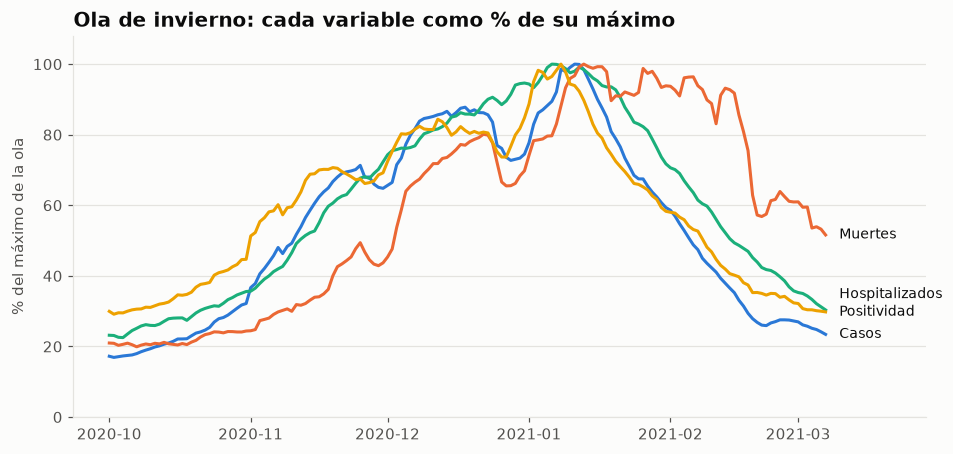

,día del máximo,días hasta bajar a la mitad,% del máximo el 07-03-2021
casos,2021-01-11,26,23
hospitalizados,2021-01-06,40,30
muertes,2021-01-13,aún no,52
positividad,2021-01-08,32,30


In [8]:
invierno = tendencias.loc["2020-10-01":]
indice = invierno / invierno.max() * 100
colores = {"casos": AZUL, "hospitalizados": VERDE, "muertes": NARANJA, "positividad": AMARILLO}

fig, ax = plt.subplots()
finales = indice.iloc[-1].sort_values()
posiciones = {}
for columna, valor in finales.items():   # separa las etiquetas al menos 5 puntos para que no se monten
    posiciones[columna] = max(valor, max(posiciones.values(), default=-10) + 5)
for columna, color in colores.items():
    ax.plot(indice.index, indice[columna], color=color)
    ax.annotate(columna.capitalize(), xy=(indice.index[-1], indice[columna].iloc[-1]),
                xytext=(indice.index[-1] + pd.Timedelta(days=3), posiciones[columna]), va="center", color=TEXTO,
                fontsize=9)
ax.set_ylim(0, 108)
ax.set_xlim(right=indice.index[-1] + pd.Timedelta(days=22))
ax.set_ylabel("% del máximo de la ola")
ax.set_title("Ola de invierno: cada variable como % de su máximo")
ax.grid(axis="x", visible=False)
plt.show()

resumen = {}
for columna in colores:
    serie = invierno[columna]
    pico = serie.idxmax()
    mitad = serie.loc[pico:][serie.loc[pico:] <= serie.max() / 2]
    resumen[columna] = {"día del máximo": pico.date(),
                        "días hasta bajar a la mitad": (mitad.index[0] - pico).days if len(mitad) else "aún no",
                        "% del máximo el 07-03-2021": round(serie.iloc[-1] / serie.max() * 100)}
pd.DataFrame(resumen).T

- **Los máximos llegan casi a la vez**, entre el 6 y el 13 de enero. En invierno la curva tuvo una meseta larga
  (noviembre a enero) y las fiestas alteraron las notificaciones de casos, y eso junta los picos.
- **Donde se ve el desfase es en la bajada:** los casos tardan 26 días en caer a la mitad, la positividad 32 y los
  hospitalizados 40.
  Las muertes, a 7 de marzo de 2021, siguen por encima de la mitad de su máximo.
- Las muertes reflejan los contagios de unas tres semanas antes. Cuando empieza a bajar una ola, todavía hay que
  esperar casi un mes para que bajen las muertes.

## 4. Comparar regiones y estados

### 4.1 Positividad por región

La positividad no depende del tamaño de la región, así que se puede comparar su evolución sin normalizar. Cada panel
destaca una región y deja las otras en gris de fondo.

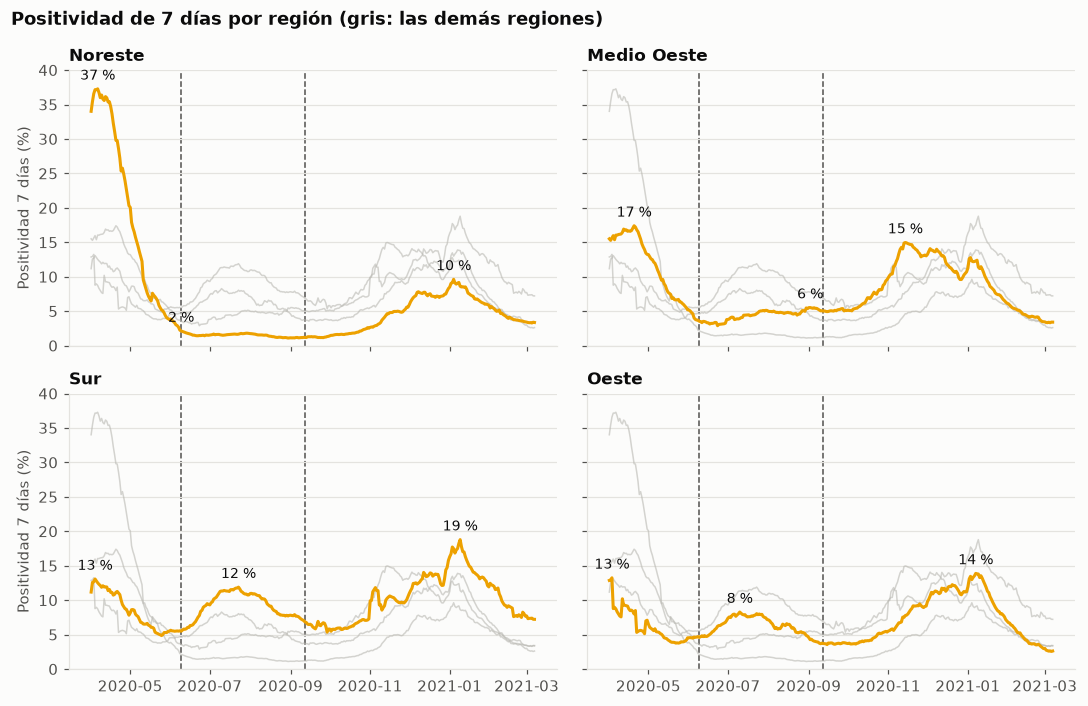

In [9]:
por_region = desde_marzo.groupby(["region", "fecha"])[["casos_nuevos", "tests_nuevos"]].sum()
casos_semana = por_region["casos_nuevos"].groupby(level="region").transform(lambda s: s.rolling(7).sum())
tests_semana = por_region["tests_nuevos"].groupby(level="region").transform(lambda s: s.rolling(7).sum())
positividad_region = (casos_semana / tests_semana * 100).unstack("region").loc["2020-04-01":, list(REGIONES)]

fig, ejes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True, sharey=True)
for ax, region in zip(ejes.flat, REGIONES):
    for otra in REGIONES:
        if otra != region:
            ax.plot(positividad_region.index, positividad_region[otra], color=GRIS, linewidth=1, alpha=0.6)
    serie = positividad_region[region]
    ax.plot(serie.index, serie, color=AMARILLO)
    lineas_olas(ax, CORTES)
    for tramo in [serie.loc[:CORTES[0]], serie.loc[CORTES[0]:CORTES[1]], serie.loc[CORTES[1]:]]:
        pico = tramo.idxmax()
        ax.annotate(f"{tramo[pico]:.0f} %", xy=(pico, tramo[pico]), xytext=(0, 6), textcoords="offset points",
                    ha="center", color=TEXTO, fontsize=9)
    ax.set_title(region, fontsize=11)
    ax.set_ylim(0, 40)
    ax.grid(axis="x", visible=False)
for ax in ejes[:, 0]:
    ax.set_ylabel("Positividad 7 días (%)")
fig.suptitle("Positividad de 7 días por región (gris: las demás regiones)", x=0.01, ha="left",
             fontweight="bold", color=TEXTO)
plt.tight_layout()
plt.show()

Las etiquetas marcan el máximo de cada ola. Empezamos en abril de 2020, porque en marzo había tan pocos tests que
la positividad salta sin sentido.

- **Noreste:** la positividad más alta de todas en la primavera de 2020 y después la más baja durante el verano y
  el otoño.
- **Sur:** su pico de verano es el más alto de las cuatro regiones, y el de invierno también.
- **Medio Oeste:** es el primero en subir en otoño. Su máximo llega en noviembre, antes que el de las demás.
- **Oeste:** sigue el patrón general, con un pico de verano moderado y otro mayor a principios de enero.

Recordatorio: cada región mezcla estados que cuentan personas y otros que cuentan muestras (notebook 03). Las
formas de las curvas son fiables; los niveles exactos, menos.

### 4.2 Cuatro estados, cuatro calendarios

Comparamos las **muertes** (media de 7 días) de cuatro estados como **% de su propio máximo**. Usamos muertes y no
casos porque en la primavera de 2020 los casos están muy infracontados. Con el % del propio máximo se pueden
comparar estados de cualquier tamaño: la normalización por población llega en la issue #6.

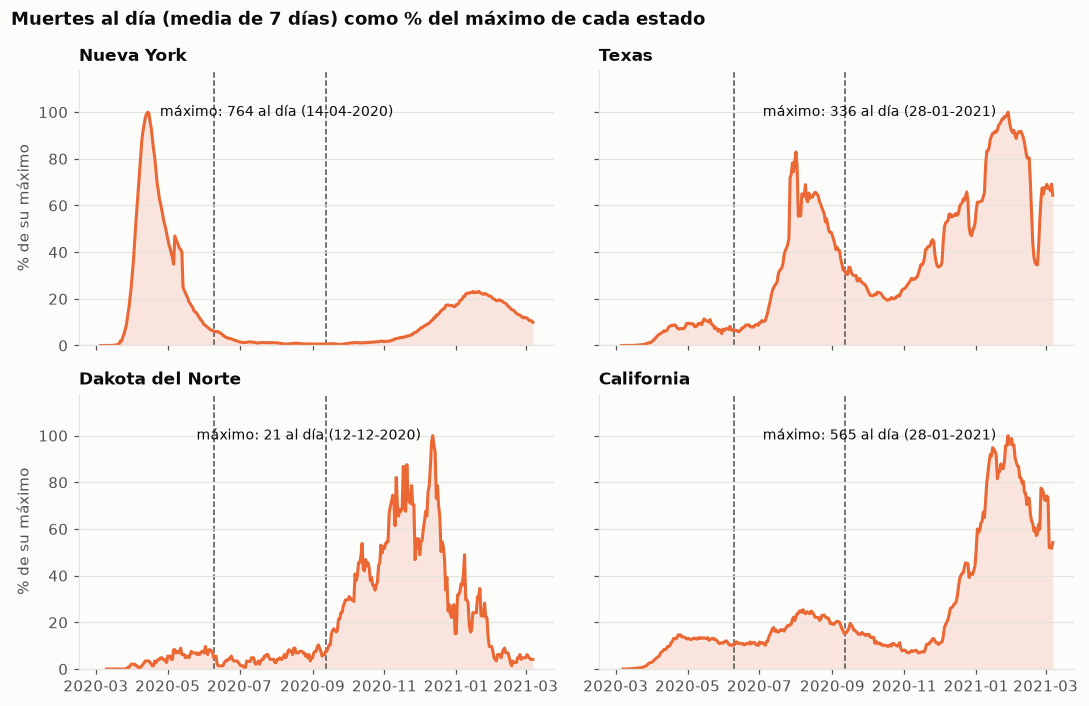

In [10]:
seleccion = {"NY": "Nueva York", "TX": "Texas", "ND": "Dakota del Norte", "CA": "California"}
fig, ejes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True, sharey=True)
for ax, (codigo, nombre) in zip(ejes.flat, seleccion.items()):
    serie = estados.loc[estados["estado"] == codigo].set_index("fecha")["muertes_nuevas_7d"].loc["2020-03-01":]
    relativa = serie / serie.max() * 100
    ax.fill_between(relativa.index, relativa, color=NARANJA, alpha=0.15, linewidth=0)
    ax.plot(relativa.index, relativa, color=NARANJA)
    lineas_olas(ax, CORTES)
    pico = relativa.idxmax()
    a_la_izquierda = pico < relativa.index[len(relativa) // 2]
    ax.annotate(f"máximo: {formato_miles(serie.max())} al día ({pico:%d-%m-%Y})", xy=(pico, 100),
                xytext=(8 if a_la_izquierda else -8, 0), textcoords="offset points", va="center",
                ha="left" if a_la_izquierda else "right", color=TEXTO, fontsize=9)
    ax.set_title(nombre, fontsize=11)
    ax.set_ylim(0, 118)
    ax.grid(axis="x", visible=False)
for ax in ejes[:, 0]:
    ax.set_ylabel("% de su máximo")
fig.suptitle("Muertes al día (media de 7 días) como % del máximo de cada estado", x=0.01, ha="left",
             fontweight="bold", color=TEXTO)
plt.tight_layout()
plt.show()

In [11]:
picos = estados.loc[estados.groupby("estado")["muertes_nuevas_7d"].idxmax(), ["estado", "ola"]]
print("Ola en la que cada estado tuvo su máximo de muertes diarias (media de 7 días):")
print(picos["ola"].value_counts().reindex(list(OLAS), fill_value=0).to_string())
print("\nEstados con el máximo en la primera ola:", ", ".join(picos.loc[picos["ola"] == list(OLAS)[0], "estado"]))

Ola en la que cada estado tuvo su máximo de muertes diarias (media de 7 días):
ola
1 · primavera 2020             8
2 · verano 2020                0
3 · otoño-invierno 2020-21    43

Estados con el máximo en la primera ola: CT, DC, LA, MA, MD, MI, NJ, NY


- **Nueva York:** casi todo ocurre en la primavera de 2020. El invierno, siendo malo, se queda muy por debajo.
- **Texas:** tiene dos olas claras, la de verano y la de invierno. La de invierno es la más alta.
- **Dakota del Norte:** su ola llega antes que en el resto del país, con el máximo en diciembre de 2020. Es el
  Medio Oeste del apartado 4.1.
- **California:** es la última en llegar al máximo, a finales de enero de 2021.

Así pasa en todo el país: **43 de los 51 estados tuvieron su peor momento en otoño-invierno y 8 en la primavera de
2020**: Nueva York, Nueva Jersey, Massachusetts, Connecticut, Maryland y DC, en el Noreste y su entorno, más Michigan
y Luisiana, con los brotes tempranos de Detroit y Nueva Orleans. Ninguno tuvo el máximo en verano, aunque en el Sur
fue una ola fuerte.

## Conclusiones

- **El nivel al que se calcula la correlación cambia la respuesta:** mezclando estados de distinto tamaño, la
  relación entre casos y positividad casi desaparece (0,21); dentro de cada estado es clara (0,68).
- **Casos, hospitalizados y muertes forman una cadena:** los hospitalizados llegan unos 3 días después de los
  casos y las muertes unos 11 días después de los hospitalizados (unas tres semanas desde los casos).
- **Correlación no es causa:** la letalidad aparente baja mientras suben los tests, pero las dos siguen la
  tendencia del tiempo. Esta matriz no demuestra por sí sola que una cause la otra.
- **Cada ola subió más que la anterior en casos, pero no en muertes:** la primera ola fue mucho mayor de lo que
  dicen sus casos.
- **Cada zona tuvo su calendario:** el Noreste en primavera, el Sur en verano, el Medio Oeste a principios del
  otoño y California al final del invierno.